![Banner](../images/09_09_banner_rs_image_classification.png)


# Imperfect labels and domain shift

Textbook classification assumes many correct labels drawn from the same place and time as the map.


## Overview

Real projects rarely have that. Labels are few because field work is expensive, they come from an older or coarser map, they contain mistakes, and the model is applied to another year or another part of the landscape than it was trained on. This notebook works through the standard remedies for each problem, and scores every one of them against reference data, because each can also make the map worse.

Two datasets on the local drive are used:

- **`Sentinel_2_UB`**: the 10-band, 10 m Sentinel-2 image of the University at Buffalo North Campus with labelled points of five classes (pavement/road, building, tree/bushes, grass, water). In notebook `09_09_01_01`, the spatial-block split put every water sample in the training blocks and none in the test blocks: the campus water is one **large pond** in the west and a few **small ponds** of one to twelve pixels in the east. Here that difference is the test case for active learning and domain shift.
- **`Corn_belt`**: the 20 m Sentinel-2 cube of the Iowa corn belt study area (2020 to 2025) built by `09_09_03_02`, with the USDA Cropland Data Layer (CDL) for every year and the 2025 USDA cultivated layer. The CDL of the mapped year is the reference; older CDL maps and the cultivated layer serve as **weak labels**; 2020 and 2025 provide a **year-to-year shift**.

Everything runs on a CPU; the two small neural-network experiments (FixMatch and the noisy-label losses) are faster on a GPU, which is used when available.


## Core concepts

### Learning objectives

1. Rank unlabelled pixels and simulate an analyst who labels the next batch.
2. Add unlabelled chips with confident pseudo-labels and with FixMatch.
3. Turn a cultivated layer and older CDL maps into training labels, with filters for confidence.
4. Compare cross-entropy with the noise-robust GCE and SCE losses under simulated label noise.
5. Diagnose domain shift on the campus water class and on the corn belt from 2020 to 2025, and try CORAL, histogram matching and TENT.
6. Check that no test pixel was used for training, pseudo-labelling or adaptation.

### Contents

1. Workflow and GeoLattice functions
2. Active learning
3. Semi-supervised learning
4. Weak labels from coarse products
5. Noisy labels
6. Domain shift
7. Check that the splits stayed apart
8. Interpretation and limitations


## Workflow and GeoLattice functions

1. Active learning: rank unlabelled pixels with `uncertainty_scores` (entropy, margin, least confidence), pick a diverse batch with `select_for_labeling`, and simulate an analyst with `active_learning_loop`.
2. Semi-supervised learning: confident pseudo-labels with `pseudo_label` and `self_training`, and FixMatch for chips with `fixmatch_loss` and `train_fixmatch`.
3. Weak labels: turn the cultivated layer and older CDL maps into training labels with `weak_labels_from_product`, with edge erosion and agreement filters for confidence.
4. Noisy labels: compare cross-entropy with the noise-robust GCE and SCE losses from `get_loss` under simulated label noise.
5. Domain shift: diagnose the UB large-pond / small-pond shift and the corn belt 2020 / 2025 shift, and try `coral`, `histogram_match` and `tent_adapt`.
6. Finish with `check_split_isolation`: no test pixel may have been used for training, pseudo-labelling or adaptation.

All functions are in `geolattice.rsense.classify.image_classification` (imported as `ic`).


### Imports, paths, and settings

The cell imports the libraries, finds the repository, checks that both datasets are on the local drive, and selects the GPU when one is available. `RF` builds the random forest used as the classical model throughout; `report` is a short helper that scores predictions against reference labels with `classification_report`.


**Installation.** This notebook needs installation option 6 (every GeoLattice module): `pip install "geolattice[all]"`. See "Installation options" in the GeoLattice README.

In [1]:
import copy  # copy a network before adapting it
import os  # CPU count
import sys  # Python import path
import time  # timing
import warnings  # warning control
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import rasterio  # raster reading
import torch  # PyTorch: FixMatch, noisy-label losses and TENT
import xarray as xr  # labelled arrays (the corn belt cubes)
from matplotlib.colors import ListedColormap  # class colours
from sklearn.ensemble import RandomForestClassifier  # the classical model

warnings.filterwarnings("ignore")  # hide library warnings

# Prefer this checkout's code when launched from the repository.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "pyproject.toml").exists() and (p / "src" / "rsense").is_dir()), None)
if ROOT is not None:  # a checkout was found
    sys.path.insert(0, str(ROOT / "src"))  # import GeoLattice from its src folder

import geolattice.rsense.classify.image_classification as ic  # imperfect-label and domain-shift tools

if ROOT is None:  # not started inside the repository
    raise FileNotFoundError("Start Jupyter from the GeoLattice checkout or one of its subdirectories")  # stop
# this notebook's folder
NOTEBOOK_DIR = ROOT / "Tutorials" / "notebooks" / "08_remote_sensing" / "09_09_image_classification"
UB_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_09_image_classification" / "Sentinel_2_UB"  # UB North Campus image and points
CACHE_DIR = NOTEBOOK_DIR / "../../../../Data/08_remote_sensing/08_09_image_classification" / "Corn_belt" / "cache_20m"  # corn belt cubes built by 09_09_03_02
# inputs not found on the local drive
missing = [str(p) for p in (UB_DIR, CACHE_DIR / "s2_20m.nc", CACHE_DIR / "labels_20m.nc") if not p.exists()]
if missing:  # stop early with the list of missing inputs
    raise FileNotFoundError("Missing on the local drive (run 09_09_03_02 for the cubes): " + ", ".join(missing))  # stop

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"  # GPU when available
SEED = 7  # random seed
ic.set_seed(SEED)  # reproducible numpy and torch randomness
rng = np.random.default_rng(SEED)  # random generator for sampling


def RF():  # the random forest used as the classical model
    # the random forest used throughout
    return RandomForestClassifier(n_estimators=200, min_samples_leaf=2, n_jobs=-1, random_state=SEED)


def report(y_true, y_pred, labels):  # overall accuracy, kappa and macro F1
    r = ic.classification_report(y_true, y_pred, labels=list(labels))  # GeoLattice accuracy report
    # the three headline scores
    return {"overall accuracy": r["overall_accuracy"], "kappa": r["kappa"], "macro F1": r["macro_f1"]}


print("GeoLattice checkout:", ROOT)  # repository path
print("device:", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "cpu")  # compute device


GeoLattice checkout: /home/zia207/Github/GeoLattice
device: NVIDIA RTX A5500 Laptop GPU


### Read the UB image and split it into a western and an eastern part

The labelled points are denser than the 10 m pixels (about eleven points per pixel), so they are reduced to one sample per labelled pixel: copies of the same pixel would otherwise sit on both sides of every split. The image is split at easting 678,640 m. The **west** holds the large pond and is the labelled pool; the **east** holds the small ponds and is the test area. Every class occurs on both sides.


In [2]:
UB_BANDS = ["B2", "B3", "B4", "B5", "B6", "B7", "B8", "B8A", "B11", "B12"]  # the ten bands
with rasterio.open(UB_DIR / "Images" / "B2.tif") as src:  # georeference of the image
    ub_transform = src.transform  # pixel -> UTM 17N
# the UB image bands as one array
ub_img = np.stack([rasterio.open(UB_DIR / "Images" / f"{b}.tif").read(1) for b in UB_BANDS]).astype("float32")
UB_CLASSES = {1: "Pavement/road", 2: "Building", 3: "Tree/bushes", 4: "Grass", 5: "Water"}  # class names
UB_COLORS = ["#8c8c8c", "#d62728", "#1b6e2f", "#9bd96b", "#1f77b4"]  # class colours

pts = pd.read_csv(UB_DIR / "Label_Point_Data" / "point_data.csv")  # all labelled points
cols, rows = ~ub_transform * (pts.x.values, pts.y.values)  # map -> pixel coordinates
pts["row"], pts["col"] = rows.astype(int), cols.astype(int)  # pixel of every point
# one row per labelled pixel
ub = pts.groupby(["row", "col"]).agg(label=("Class_ID", "first"), x=("x", "mean"), y=("y", "mean")).reset_index()
ub["id"] = ["ub:" + f"{r}_{c}" for r, c in zip(ub.row, ub.col)]  # unique pixel id
X_ub = ub_img[:, ub.row, ub.col].T  # (pixel, band) spectra
y_ub = ub.label.values  # their classes
UB_SPLIT_X = 678640  # easting of the split
west, east = (ub.x < UB_SPLIT_X).values, (ub.x >= UB_SPLIT_X).values  # pool (west) and test (east)
print(f"{len(pts)} points -> {len(ub)} labelled pixels")  # deduplication
# class counts in the western pool and eastern test area
pd.DataFrame({"west (pool)": pd.Series(y_ub[west]).value_counts(), "east (test)": pd.Series(y_ub[east]).value_counts()}) \
    .rename(index=UB_CLASSES).fillna(0).astype(int)  # samples per class and side

23945 points -> 2135 labelled pixels


,west (pool),east (test)
Pavement/road,296,218
Building,316,146
Tree/bushes,200,438
Grass,68,365
Water,53,35


### Read the corn belt cube and labels

From the 20 m cube, the clearest August image of 2020 and of 2025 are kept (ten bands each, surface reflectance). The label file holds the CDL of every year, recoded to six classes (corn, soybeans, grass/pasture, developed, wetland/forest, other; `-1` is no data), and the 2025 cultivated layer (1 = not cultivated, 2 = cultivated). As in `07_08_05_01`, the eastern third of the area is the test area and a 1.6 km strip west of it is left unused, so that training and test pixels are not neighbours. Random samples of 30,000 western and 30,000 eastern pixels are drawn once and reused by every corn belt experiment.


In [3]:
s2 = xr.open_dataarray(CACHE_DIR / "s2_20m.nc")  # (time, band, y, x) reflectance, opened lazily
labels = xr.open_dataset(CACHE_DIR / "labels_20m.nc").load()  # CDL per year and cultivated layer
CRS = labels.spatial_ref.attrs["crs_wkt"]  # map projection
CB_CLASSES = ["Corn", "Soybeans", "Grass/pasture", "Developed", "Wetland/forest", "Other"]  # six classes
K = len(CB_CLASSES)  # number of classes
img = {y: s2.sel(time=f"{y}-08").isel(time=0).load() for y in (2020, 2025)}  # one August image per year
for y, a in img.items():  # report the dates used
    print(y, "image:", str(a.time.values)[:10], dict(a.sizes))  # year, image date and size
cdl = {int(y): labels.cdl.sel(year=y).values for y in labels.year.values}  # CDL per year (y, x)
H, W = cdl[2025].shape  # grid size

xx = np.broadcast_to(labels.x.values, (H, W))  # easting of every pixel
x_split = labels.x.values.min() + (2 / 3) * np.ptp(labels.x.values)  # boundary of the eastern third
valid = np.isfinite(img[2020].values).all(axis=0) & np.isfinite(img[2025].values).all(axis=0)  # clear both years
valid &= (cdl[2020] >= 0) & (cdl[2025] >= 0)  # labelled both years
west_pix = np.flatnonzero((valid & (xx < x_split - 1600)).ravel())  # western pixels outside the buffer
east_pix = np.flatnonzero((valid & (xx >= x_split)).ravel())  # eastern (test) pixels
cb_train = rng.choice(west_pix, 30000, replace=False)  # western sample
cb_test = rng.choice(east_pix, 30000, replace=False)  # eastern sample


def features(year, pix):  # (pixel, band) reflectance of one year's August image
    # features of the chosen pixels for a year
    return img[year].values.reshape(len(img[year].band), -1)[:, pix].T.astype("float32")


def cdl_at(year, pix):  # CDL class of the given pixels
    return cdl[year].ravel()[pix]  # labels of the chosen pixels for a year


print(f"west sample {len(cb_train)}, east sample {len(cb_test)} pixels; 2025 classes in the east:",  # sample sizes and eastern classes
      pd.Series(cdl_at(2025, cb_test)).map(dict(enumerate(CB_CLASSES))).value_counts().to_dict())

2020 image: 2020-08-27 {'band': 10, 'y': 1456, 'x': 1516}
2025 image: 2025-08-26 {'band': 10, 'y': 1456, 'x': 1516}
west sample 30000, east sample 30000 pixels; 2025 classes in the east: {'Corn': 15135, 'Soybeans': 11951, 'Developed': 1326, 'Grass/pasture': 1032, 'Other': 351, 'Wetland/forest': 205}


## Active learning

### Which pixel should be labelled next?

Active learning lets the model choose what the analyst labels next: the pixels it is least sure about, rather than random ones. `uncertainty_scores` turns class probabilities into one uncertainty value per pixel with three common rules:

- **entropy**: $-\sum_k p_k \log p_k$, high when the probability is spread over many classes;
- **margin**: one minus the gap between the two most likely classes, high when the top two are close;
- **least confidence**: one minus the top probability.

A random forest is trained on three labelled pixels per class from the west. The map shows its entropy over the whole image and the ten pixels `select_for_labeling` picks from the western pool. With `embeddings`, it first takes the 50 most uncertain pixels, groups them into ten clusters (k-means on the spectra) and keeps the most uncertain pixel of each cluster, so the batch is not ten copies of the same confusing spectrum.


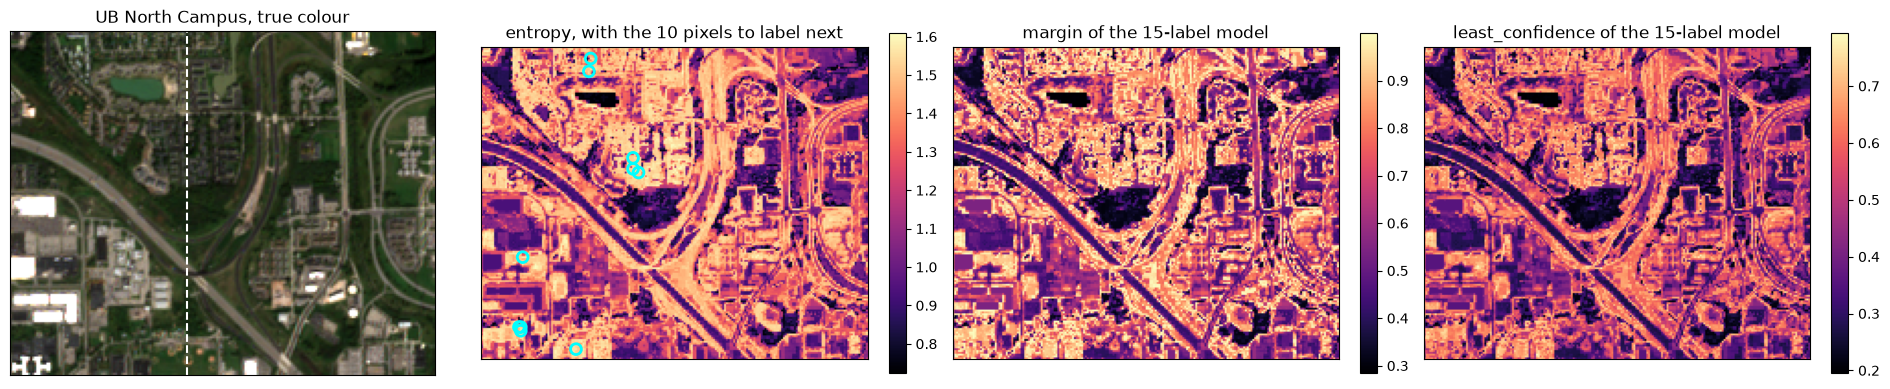

classes of the 10 chosen pixels: {'Building': 7, 'Pavement/road': 3}


In [4]:
pool_idx = np.flatnonzero(west)  # western pixels: the pool the analyst can label
seed_idx = np.concatenate([rng.choice(pool_idx[y_ub[pool_idx] == k], 3, replace=False) for k in UB_CLASSES])  # 3 per class
model0 = RF().fit(X_ub[seed_idx], y_ub[seed_idx])  # first model from 15 labels
full = ub_img.reshape(len(UB_BANDS), -1).T  # every image pixel as a spectrum
p_full = model0.predict_proba(full)  # class probabilities everywhere
# uncertainty maps by three scores
unc = {s: ic.uncertainty_scores(p_full, s).reshape(ub_img.shape[1:]) for s in ("entropy", "margin", "least_confidence")}
rest = np.setdiff1d(pool_idx, seed_idx)  # unlabelled pool pixels
# the 10 most uncertain pixels
pick = rest[ic.select_for_labeling(model0.predict_proba(X_ub[rest]), 10, strategy="entropy",
                                   embeddings=X_ub[rest], seed=SEED)]  # ten diverse, uncertain pixels

rgb = np.clip(ub_img[[2, 1, 0]].transpose(1, 2, 0) / np.percentile(ub_img[[2, 1, 0]], 98), 0, 1)  # true colour
fig, ax = plt.subplots(1, 4, figsize=(19, 4.6))  # four panels
ax[0].imshow(rgb); ax[0].set_title("UB North Campus, true colour")  # the image
ax[0].axvline((UB_SPLIT_X - ub_transform.c) / ub_transform.a, color="w", ls="--")  # west / east boundary
for a, s in zip(ax[1:], unc):  # one uncertainty map per rule
    im = a.imshow(unc[s], cmap="magma"); a.set_title(f"{s} of the 15-label model")  # the map
    plt.colorbar(im, ax=a, fraction=0.04)  # its scale
ax[1].scatter(ub.col[pick], ub.row[pick], s=60, facecolors="none", edgecolors="cyan", lw=2)  # chosen pixels
ax[1].set_title("entropy, with the 10 pixels to label next")  # title
for a in ax:  # every panel
    a.set_xticks([]); a.set_yticks([])  # no ticks
plt.tight_layout(); plt.show()  # arrange and draw
print("classes of the 10 chosen pixels:", pd.Series(y_ub[pick]).map(UB_CLASSES).value_counts().to_dict())  # what the model asked for

The three rules agree on where the 15-label model is unsure: roofs, parking lots, roads and the edges between classes. The ten pixels chosen for labelling are all buildings and pavement in the built-up west.


### Simulate the analyst with `active_learning_loop`

`active_learning_loop` trains the model, scores the pool, asks an **oracle** for the labels of the chosen pixels, adds them and retrains. Here the oracle is the reference label of the pixel, standing in for an analyst at the screen. Each strategy starts from the same 15 labels and adds ten pixels in each of 15 rounds; random sampling is the baseline every strategy must beat. The accuracy after each round is measured on the eastern test pixels, which are never offered to the oracle. Everything is repeated with three different starting sets.


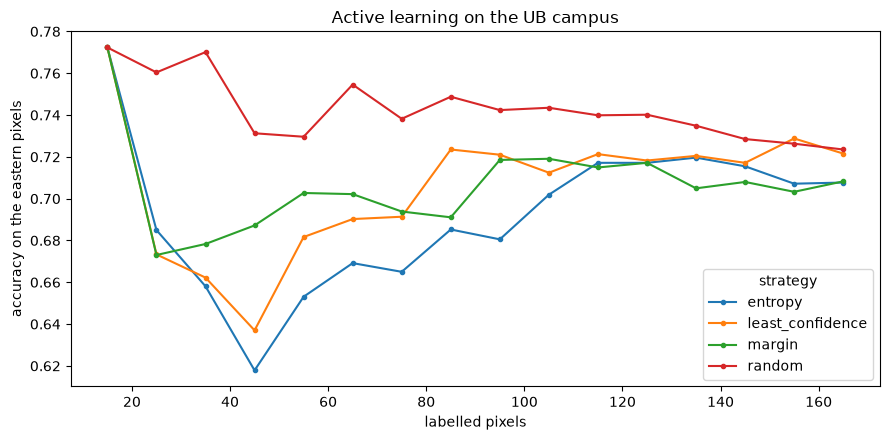

strategy,entropy,least_confidence,margin,random
labels,,,,
15.0,0.772,0.772,0.772,0.772
65.0,0.669,0.690,0.702,0.755
115.0,0.717,0.721,0.715,0.740
165.0,0.708,0.722,0.708,0.724


In [5]:
STRATEGIES = ["entropy", "margin", "least_confidence"]  # uncertainty rules
al_rows = []  # one row per strategy, repeat and round
for rep_i in range(3):  # three different starting sets
    r = np.random.default_rng(SEED + rep_i)  # generator of this repeat
    start = np.concatenate([r.choice(pool_idx[y_ub[pool_idx] == k], 3, replace=False) for k in UB_CLASSES])  # 15 labels
    pool = np.setdiff1d(pool_idx, start)  # the rest of the west
    for s in STRATEGIES:  # each rule
        res = ic.active_learning_loop(RF, X_ub[start], y_ub[start], X_ub[pool], oracle=lambda i: y_ub[pool[i]],  # train, query the oracle, retrain
                                      rounds=15, batch=10, strategy=s, X_val=X_ub[east], y_val=y_ub[east],
                                      diversity=True, seed=SEED)  # train, query, retrain
        for _, h in res["history"].iterrows():  # each round
            # learning curve point
            al_rows.append({"strategy": s, "repeat": rep_i, "labels": h.n_labeled, "accuracy": h.val_accuracy})
    order = r.permutation(pool)  # random sampling: label the pool in a random order
    for k in range(16):  # same label budget as the loop
        lab = np.concatenate([start, order[:10 * k]])  # labels so far
        acc = (RF().fit(X_ub[lab], y_ub[lab]).predict(X_ub[east]) == y_ub[east]).mean()  # test accuracy
        # random-sampling curve point
        al_rows.append({"strategy": "random", "repeat": rep_i, "labels": len(lab), "accuracy": acc})
al = pd.DataFrame(al_rows)  # as a table
curve = al.groupby(["strategy", "labels"]).accuracy.mean().unstack(0)  # mean of the three repeats
ax = curve.plot(marker="o", ms=3, figsize=(9, 4.5))  # one curve per strategy
# axes and title
ax.set(xlabel="labelled pixels", ylabel="accuracy on the eastern pixels", title="Active learning on the UB campus")
plt.tight_layout(); plt.show()  # draw
curve.iloc[[0, 5, 10, 15]].round(3)  # accuracy at 15, 65, 115 and 165 labels

**Reading the curves.** On this campus, random sampling beats all three uncertainty rules, and the accuracy on the east even falls as more western labels are added, for random sampling too. The uncertainty rules spend their labels on the hardest western pixels (roofs, parking lots and their edges), while the eastern test area is mostly trees and grass, and every round moves the training set further towards the western mix of classes. This is the main risk of active learning: it optimises for the pool, not for the place where the map will be used.


## Semi-supervised learning

### Self-training with confident pseudo-labels

Semi-supervised learning uses the unlabelled pixels too. `pseudo_label` keeps the predictions a model is confident about (top probability above a threshold) as if they were labels; `self_training` repeats this: fit on the labelled pixels, pseudo-label the confident part of the unlabelled pool, refit on both, and so on. A pseudo-label is only as good as the model that made it, so a wrong but confident prediction is learned again with more weight: the threshold trades the number of new labels against their quality.

The test is corn belt pixels from the 2025 August image: 20 labelled pixels per class from the west, the other 29,880 western pixels as the unlabelled pool, and the eastern pixels for scoring. The table compares thresholds 0.8, 0.9 and 0.97 with the supervised model trained on the 120 labels alone; the last columns check the pseudo-labels against the CDL.


In [6]:
Xw, yw = features(2025, cb_train), cdl_at(2025, cb_train)  # western pixels and their CDL classes
Xe, ye = features(2025, cb_test), cdl_at(2025, cb_test)  # eastern pixels and their CDL classes
few = np.concatenate([rng.choice(np.flatnonzero(yw == k), 20, replace=False) for k in range(K)])  # 20 per class
unl = np.setdiff1d(np.arange(len(yw)), few)  # the unlabelled pool
base = RF().fit(Xw[few], yw[few])  # supervised only
st_rows = {"supervised, 120 labels": {**report(ye, base.predict(Xe), range(K)), "pseudo-labels": 0,  # supervised baseline
                                       "pseudo-label accuracy": np.nan}}
for thr in (0.8, 0.9, 0.97):  # three confidence thresholds
    st = ic.self_training(RF, Xw[few], yw[few], Xw[unl], threshold=thr, rounds=3, max_per_round=5000)  # 3 rounds
    pl = unl[st["pseudo_labeled"]]  # pixels that received a pseudo-label
    pl_acc = (st["model"].predict(Xw[pl]) == yw[pl]).mean() if len(pl) else np.nan  # pseudo-labels vs CDL
    st_rows[f"self-training, threshold {thr}"] = {**report(ye, st["model"].predict(Xe), range(K)),  # scores and pseudo-label quality
                                                   "pseudo-labels": len(pl), "pseudo-label accuracy": pl_acc}
idx, lab = ic.pseudo_label(base.predict_proba(Xw[unl]), threshold=0.9, classes=base.classes_)  # one step by hand
print(f"pseudo_label at 0.9 on the first model: {len(idx)} of {len(unl)} pixels, "  # one pseudo-labelling step
      f"{(lab == yw[unl][idx]).mean():.1%} agree with the CDL")
pd.DataFrame(st_rows).T.round(3)  # show the comparison

pseudo_label at 0.9 on the first model: 1726 of 29880 pixels, 99.1% agree with the CDL


,overall accuracy,kappa,macro F1,pseudo-labels,pseudo-label accuracy
"supervised, 120 labels",0.826,0.720,0.521,0.0,NaN
"self-training, threshold 0.8",0.831,0.723,0.522,14771.0,0.954
"self-training, threshold 0.9",0.813,0.697,0.509,7067.0,0.976
"self-training, threshold 0.97",0.825,0.720,0.521,192.0,0.995


**Reading the self-training results.** The pseudo-labels are very accurate (95 % to 99.5 % agree with the CDL), yet the test score barely moves. The model is confident where the task is easy, so the confident pixels are typical corn and soybean pixels it already classifies correctly, and they add little that the 120 labels did not already say. A lower threshold adds more pseudo-labels and more errors with them.


### FixMatch for image chips

FixMatch (Sohn et al. 2020) is the semi-supervised method most used for deep networks. For every unlabelled chip, the model sees a **weakly** augmented version (rotation or flip) and a **strongly** augmented one (crop, brightness, contrast and noise). When the prediction on the weak view is confident (above 0.95), it becomes the target for the strong view. `fixmatch_loss` adds this consistency term to the ordinary cross-entropy on the labelled chips, and `train_fixmatch` runs the training loop.

The chips are 16 × 16 pixels (320 m) of the 2025 August image, labelled with their CDL majority class when it covers at least 60 % of the chip. Ten chips per class from the west are labelled; every western chip is unlabelled data; the eastern chips are the test set. The baseline is the same network trained with the same loop and `lambda_u=0`, which switches the unlabelled term off.


In [7]:
CHIP = 16  # chip size in pixels
NR, NC = H // CHIP, W // CHIP  # chip rows and columns
a25 = img[2025].values[:, :NR * CHIP, :NC * CHIP]  # 2025 image cropped to whole chips
chips = a25.reshape(10, NR, CHIP, NC, CHIP).transpose(1, 3, 0, 2, 4).reshape(NR * NC, 10, CHIP, CHIP)  # (chip, band, y, x)
lab_c = cdl[2025][:NR * CHIP, :NC * CHIP].reshape(NR, CHIP, NC, CHIP).transpose(0, 2, 1, 3).reshape(NR * NC, -1)  # pixels
counts = np.stack([(lab_c == k).sum(axis=1) for k in range(K)], axis=1)  # class counts per chip
chip_y, purity = counts.argmax(axis=1), counts.max(axis=1) / CHIP ** 2  # majority class and its share
chip_x = labels.x.values[:NC * CHIP].reshape(NC, CHIP).mean(axis=1)[np.arange(NR * NC) % NC]  # chip-centre easting
ok = np.isfinite(chips).all(axis=(1, 2, 3))  # chips with no missing pixel
c_west = np.flatnonzero(ok & (chip_x < x_split - 1600))  # western chips
c_test = np.flatnonzero(ok & (chip_x >= x_split) & (purity >= 0.6))  # labelled eastern chips
pure_w = {k: c_west[(chip_y[c_west] == k) & (purity[c_west] >= 0.6)] for k in range(K)}  # pure western chips per class
c_lab = np.concatenate([rng.choice(v, min(10, len(v)), replace=False) for v in pure_w.values()])  # up to 10 per class
mu = chips[c_west].mean(axis=(0, 2, 3), keepdims=True)[0]  # per-band mean of the western chips
sd = chips[c_west].std(axis=(0, 2, 3), keepdims=True)[0]  # per-band standard deviation
norm = lambda i: (chips[i] - mu) / sd  # standardised chips
lab_ds = ic.ChipDataset(norm(c_lab), chip_y[c_lab])  # labelled chips
unl_ds = ic.ChipDataset(norm(c_west))  # unlabelled chips (all of the west)
test_ds = ic.ChipDataset(norm(c_test), chip_y[c_test])  # test chips
print(f"labelled {len(lab_ds)}, unlabelled {len(unl_ds)}, test {len(test_ds)} chips")  # dataset sizes


def fixmatch_run(lambda_u):  # train the same small CNN with or without the unlabelled term
    torch.manual_seed(SEED)  # identical initial weights
    net = ic.build_cnn("simple_cnn", in_channels=10, num_classes=K)  # small CNN for 16-pixel chips
    sampler = torch.utils.data.RandomSampler(lab_ds, replacement=True, num_samples=len(unl_ds))  # repeat labels
    lab_loader = torch.utils.data.DataLoader(lab_ds, batch_size=64, sampler=sampler)  # as many batches as unlabelled
    unl_loader = ic.as_loader(unl_ds, 64, shuffle=True, seed=SEED)  # unlabelled batches
    # FixMatch training
    hist = ic.train_fixmatch(net, lab_loader, unl_loader, epochs=30, lr=1e-3, threshold=0.95, lambda_u=lambda_u,
                             device=DEVICE, seed=SEED, verbose=False)  # the training loop
    pred = ic.predict_proba_batches(net, test_ds, device=DEVICE).argmax(1)  # test predictions
    # scores and final mask rate
    return {**report(chip_y[c_test], pred, range(K)), "final mask rate": hist["mask_rate"][-1]}


t0 = time.time()  # start the timer
fm = {"supervised (lambda_u = 0)": fixmatch_run(0.0), "FixMatch (lambda_u = 1)": fixmatch_run(1.0)}  # both runs
# run time
print(f"both runs in {time.time() - t0:.0f} s; mask rate = share of unlabelled chips above the 0.95 threshold")
pd.DataFrame(fm).T.round(3)  # show the comparison

labelled 57, unlabelled 5212, test 2284 chips


both runs in 52 s; mask rate = share of unlabelled chips above the 0.95 threshold


,overall accuracy,kappa,macro F1,final mask rate
supervised (lambda_u = 0),0.861,0.752,0.461,0.590
FixMatch (lambda_u = 1),0.649,0.423,0.520,0.849


**Reading the FixMatch results.** FixMatch raised the macro F1 but cut the overall accuracy by more than 20 points. The labelled set is balanced (up to ten chips per class) while the landscape is almost all corn and soybeans, and the mask rate shows that most unlabelled chips passed the 0.95 threshold: the network most likely spreads its confident small-class predictions over many crop chips and then trains on them. A semi-supervised method amplifies whatever bias the labelled set has. The class mix of the labelled chips should match the mapped area, or the thresholds be set per class, as later FixMatch variants do.


## Weak labels from coarse products

### Crop / non-crop from the cultivated layer and last year's CDL

Existing maps are a cheap source of training labels. They are "weak" because they describe another year, a coarser resolution or a broader class. `weak_labels_from_product` maps a product's codes to the task's classes, sends every unmapped code to `ignore_index` (-100), and with `erode` drops the pixels next to class edges, where coarse products are least reliable. The task is a 2025 crop / non-crop map (corn and soybeans against grass, developed and wetland/forest; "other" is left out because it mixes other crops with non-crop land). Four sources of weak labels are compared with the 2025 CDL itself (the clean upper bound):

- the **2025 cultivated layer** (a multi-year USDA product of land that has been cropped);
- the **2024 CDL** (last year's map);
- the same two with **edges eroded** by one pixel;
- only the pixels where both products **agree** (an agreement filter).

For each source, the table gives the share of western pixels that keep a label, how often that label agrees with the 2025 CDL, and the test scores of a random forest trained on it, against the 2025 CDL of the eastern pixels. F1 of the non-crop class is reported because non-crop is only a few per cent of the area.


In [8]:
def crop_of(c):  # 2025 reference: 1 = crop (corn, soybeans), 0 = non-crop, -100 = not evaluated ("other", no data)
    out = np.full(c.shape, -100)  # not evaluated by default
    out[np.isin(c, [0, 1])], out[np.isin(c, [2, 3, 4])] = 1, 0  # crop and non-crop
    return out  # the result


cult_da = labels.cultivated  # 1 = not cultivated, 2 = cultivated
cdl24_da = labels.cdl.sel(year=2024)  # last year's CDL (six classes)
CDL_TO_CROP = {0: 1, 1: 1, 2: 0, 3: 0, 4: 0}  # corn, soybeans -> crop; grass, developed, wetland/forest -> non-crop
weak = {  # label source -> weak label map
    "cultivated layer": ic.weak_labels_from_product(cult_da, {1: 0, 2: 1}),
    "CDL 2024": ic.weak_labels_from_product(cdl24_da, CDL_TO_CROP),
    "cultivated layer, eroded 1 px": ic.weak_labels_from_product(cult_da, {1: 0, 2: 1}, erode=1),
    "CDL 2024, eroded 1 px": ic.weak_labels_from_product(cdl24_da, CDL_TO_CROP, erode=1),
}
a, b = weak["cultivated layer"].values, weak["CDL 2024"].values  # the two raw sources
weak["agreement of both"] = weak["CDL 2024"].copy(data=np.where((a == b) & (a >= 0), a, -100))  # keep agreement only

truth_w, truth_e = crop_of(cdl_at(2025, cb_train)), crop_of(cdl_at(2025, cb_test))  # 2025 reference, west and east
ev = truth_e >= 0  # evaluated eastern pixels
wk_rows = {}  # one row per label source
for name, da in [("CDL 2025 (clean labels)", None), *weak.items()]:  # each source
    yl = truth_w if da is None else da.values.ravel()[cb_train]  # its labels on the western sample
    keep = yl >= 0  # pixels with a label
    agree = np.mean(yl[keep & (truth_w >= 0)] == truth_w[keep & (truth_w >= 0)])  # agreement with the 2025 CDL
    pred = RF().fit(Xw[keep], yl[keep]).predict(Xe[ev])  # train on the source, predict the east
    r = ic.classification_report(truth_e[ev], pred, labels=[0, 1])  # scores against the 2025 CDL
    wk_rows[name] = {"west pixels labelled": keep.mean(), "label agreement with CDL 2025": agree,  # coverage, agreement and test scores
                     "test accuracy": r["overall_accuracy"], "test kappa": r["kappa"],
                     "test F1 non-crop": r["per_class"].loc[0, "f1"]}
pd.DataFrame(wk_rows).T.round(3)  # show the comparison

,west pixels labelled,label agreement with CDL 2025,test accuracy,test kappa,test F1 non-crop
CDL 2025 (clean labels),0.992,1.000,0.955,0.705,0.730
cultivated layer,1.000,0.966,0.955,0.682,0.707
CDL 2024,0.993,0.970,0.953,0.671,0.696
"cultivated layer, eroded 1 px",0.892,0.985,0.944,0.555,0.582
"CDL 2024, eroded 1 px",0.885,0.988,0.947,0.602,0.629
agreement of both,0.953,0.988,0.955,0.692,0.716


**Reading the crop / non-crop results.** Both weak sources agree with the 2025 CDL on about 97 % of the western pixels, and a classifier trained on either is almost as good as one trained on the 2025 CDL itself: for a stable land use, last year's map or a multi-year product is a usable source of labels. Eroding the class edges raised the label agreement but lowered the test scores, most of all for non-crop: one 20 m pixel of erosion deletes the roads, ditches, farmsteads and stream banks that make up much of the non-crop class, so the classifier never sees them. The agreement filter kept 95 % of the pixels and did as well as the clean labels.


### Corn / soybeans from the crop rotation, with a confidence filter

The cultivated layer cannot separate crops, but the CDL history can, through the corn-soybean rotation that dominates Iowa. A weak 2025 label is "the opposite of 2024": corn after soybeans and soybeans after corn (`weak_labels_from_product` with the mapping corn → soybeans, soybeans → corn). Not every field rotates every year, so the **confidence filter** keeps only fields that alternated strictly in 2022, 2023 and 2024 (for example corn, soybeans, corn), whose next step is the most predictable. The test is a corn / soybean classifier scored on the eastern pixels that the 2025 CDL calls corn or soybeans.


In [9]:
rot = ic.weak_labels_from_product(cdl24_da, {0: 1, 1: 0})  # 2025 guess: the other crop than in 2024
c22, c23, c24 = (labels.cdl.sel(year=y).values for y in (2022, 2023, 2024))  # three years of history
strict = np.isin(c24, [0, 1]) & (c22 == c24) & (c23 == 1 - c24)  # strict alternation, e.g. corn-soy-corn
rot_conf = rot.copy(data=np.where(strict, rot.values, -100))  # keep the confident fields only
cs_w, cs_e = np.isin(cdl_at(2025, cb_train), [0, 1]), np.isin(cdl_at(2025, cb_test), [0, 1])  # corn/soy pixels
rot_rows = {}  # one row per label source
# each label source
for name, lab_map in [("CDL 2025 (clean labels)", None), ("rotation rule", rot), ("rotation rule, strict alternation", rot_conf)]:
    yl = cdl_at(2025, cb_train) if lab_map is None else lab_map.values.ravel()[cb_train]  # labels of the western sample
    keep = cs_w & (yl >= 0) if lab_map is None else (yl >= 0)  # labelled western pixels
    agree = np.mean(yl[keep & cs_w] == cdl_at(2025, cb_train)[keep & cs_w])  # agreement with the 2025 CDL
    pred = RF().fit(Xw[keep], yl[keep]).predict(Xe[cs_e])  # train and predict the eastern corn/soy pixels
    rot_rows[name] = {"west pixels labelled": keep.mean(), "label agreement with CDL 2025": agree,  # coverage, agreement and test scores
                      **report(cdl_at(2025, cb_test)[cs_e], pred, [0, 1])}
pd.DataFrame(rot_rows).T.round(3)  # show the comparison

,west pixels labelled,label agreement with CDL 2025,overall accuracy,kappa,macro F1
CDL 2025 (clean labels),0.882,1.000,0.978,0.955,0.977
rotation rule,0.888,0.836,0.899,0.800,0.899
"rotation rule, strict alternation",0.679,0.909,0.944,0.887,0.943


The rotation rule alone is right for 84 % of the western pixels. The strict-alternation filter keeps about two thirds of them and raises their agreement to 91 %, and the classifier trained on the filtered labels gains about 4.5 points of accuracy (from 89.9 % to 94.4 %), against 97.8 % with the true 2025 labels. Here fewer but better labels win.


## Noisy labels

### GCE and SCE against cross-entropy

Even good labels contain mistakes: digitising errors, mixed pixels, a field that changed. Cross-entropy (CE) punishes a confident disagreement with the label without limit, so a network eventually memorises the wrong labels too. Two losses from `get_loss` limit this:

- **Generalized cross-entropy (GCE**, Zhang and Sabuncu 2018): $(1 - p_y^q)/q$, which moves from CE ($q \to 0$) towards the mean absolute error ($q = 1$); the loss of a sample the model strongly disagrees with is bounded, so a wrong label cannot dominate training. `q = 0.7` here.
- **Symmetric cross-entropy (SCE**, Wang et al. 2019): CE plus a reverse cross-entropy term that treats the prediction as the target, $\alpha \, \mathrm{CE} + \beta \, \mathrm{RCE}$ with $\alpha = 0.1$, $\beta = 1$.

The experiment corrupts the labels of the 30,000 western corn belt pixels on purpose and trains the same small network (two hidden layers with batch normalisation) with each loss: **symmetric** noise replaces 20 % or 40 % of the labels by a random other class; **asymmetric** noise swaps 30 % of corn and soybean labels with each other, the realistic error in this landscape. The test pixels in the east keep their correct labels.


In [10]:
F_MU, F_SD = Xw.mean(0), Xw.std(0)  # standardisation from the western pixels
Xw_t = torch.tensor((Xw - F_MU) / F_SD, dtype=torch.float32)  # standardised western features
Xe_t = torch.tensor((Xe - F_MU) / F_SD, dtype=torch.float32)  # standardised eastern features


def make_mlp():  # small network with batch normalisation (TENT below also needs it)
    torch.manual_seed(SEED)  # identical initial weights for every run
    # a small MLP for the 10 bands
    return torch.nn.Sequential(torch.nn.Linear(10, 128), torch.nn.BatchNorm1d(128), torch.nn.ReLU(),
                               torch.nn.Linear(128, 128), torch.nn.BatchNorm1d(128), torch.nn.ReLU(),
                               torch.nn.Linear(128, K))


def train_mlp(X, y, loss_name="ce", epochs=40):  # mini-batch training with one loss
    net, loss_fn = make_mlp().to(DEVICE), ic.get_loss(loss_name).to(DEVICE)  # network and loss
    opt = torch.optim.AdamW(net.parameters(), lr=1e-3, weight_decay=1e-4)  # optimiser
    g = torch.Generator().manual_seed(SEED)  # reproducible shuffling
    y = torch.as_tensor(y, dtype=torch.long)  # labels as a tensor
    for _ in range(epochs):  # epochs
        net.train()  # training mode
        for b in torch.randperm(len(X), generator=g).split(512):  # shuffled batches of 512
            loss = loss_fn(net(X[b].to(DEVICE)), y[b].to(DEVICE))  # loss of the batch
            opt.zero_grad(); loss.backward(); opt.step()  # one update
    return net.eval()  # evaluation mode


def predict_mlp(net, X):  # class predictions
    with torch.no_grad():  # inference only
        return net(X.to(DEVICE)).argmax(1).cpu().numpy()  # arg-max of the scores


def add_noise(y, kind, rate, seed=SEED):  # corrupt a share of the labels
    r, y = np.random.default_rng(seed), y.copy()  # generator and a copy
    if kind == "symmetric":  # any class -> a random other class
        flip = r.random(len(y)) < rate  # labels to corrupt
        y[flip] = (y[flip] + r.integers(1, K, flip.sum())) % K  # a different class
    else:  # corn <-> soybeans
        flip = np.isin(y, [0, 1]) & (r.random(len(y)) < rate)  # corn and soybean labels to swap
        y[flip] = 1 - y[flip]  # swap them
    return y  # the noisy labels


# noise settings: name, type and rate
NOISE = [("clean", "symmetric", 0.0), ("symmetric 20 %", "symmetric", 0.2), ("symmetric 40 %", "symmetric", 0.4),
         ("corn/soy swap 30 %", "asymmetric", 0.3)]  # noise settings
noise_rows = []  # one row per setting and loss
t0 = time.time()  # start the timer
for label, kind, rate in NOISE:  # each noise setting
    y_noisy = add_noise(yw, kind, rate)  # corrupted training labels
    for loss_name in ("ce", "gce", "sce"):  # each loss
        pred = predict_mlp(train_mlp(Xw_t, y_noisy, loss_name), Xe_t)  # train on noisy, predict the east
        noise_rows.append({"noise": label, "actual label error": np.mean(y_noisy != yw), "loss": loss_name.upper(),  # one result row
                           **report(ye, pred, range(K))})
noise_tab = pd.DataFrame(noise_rows)  # as a table
print(f"12 networks trained in {time.time() - t0:.0f} s")  # run time
noise_tab.pivot_table(index=["noise", "actual label error"], columns="loss", values=["overall accuracy", "macro F1"]).round(3)  # accuracy and macro F1 per loss

12 networks trained in 55 s


macro F1               overall accuracy  \
loss                                        CE    GCE    SCE               CE   
noise              actual label error                                           
clean              0.000000              0.695  0.657  0.681            0.931   
corn/soy swap 30 % 0.262833              0.694  0.662  0.672            0.929   
symmetric 20 %     0.197067              0.679  0.683  0.669            0.930   
symmetric 40 %     0.400500              0.647  0.660  0.653            0.928   

                                                     
loss                                     GCE    SCE  
noise              actual label error                
clean              0.000000            0.930  0.931  
corn/soy swap 30 % 0.262833            0.928  0.929  
symmetric 20 %     0.197067            0.930  0.930  
symmetric 40 %     0.400500            0.927  0.927

**Reading the noise results.** The overall accuracy hardly moves, even with 40 % of the labels wrong. With 30,000 pixels and a small network, cross-entropy does not memorise the noise: every spectral region still holds a majority of correct labels, and the network learns the majority. The 30 % corn/soybean swap changed nothing for the same reason. The macro F1, which the small classes drive, drops with symmetric noise because their few correct labels are diluted; there GCE and SCE recover a little at 40 % noise, while GCE costs a few points on clean labels.


## Domain shift

### The UB water class: one large pond, several small ones

A model meets **domain shift** when the data it is applied to differ from the data it learned from. On the UB campus the shift is inside one class. The only water in the west is the large pond (about 38 pixels of open water); the water in the east is four small ponds of one to twelve pixels, whose pixels mix water with banks, trees and grass. The cell trains a random forest on all western pixels and scores it on the east, class by class, and plots the mean spectrum of the large pond, the small ponds and the two vegetation classes.


,precision,recall,f1,support
Pavement/road,0.496,0.564,0.528,218
Building,0.309,0.459,0.369,146
Tree/bushes,0.818,0.781,0.799,438
Grass,0.924,0.797,0.856,365
Water,1.000,0.114,0.205,35


eastern water pixels predicted as: {'Pavement/road': 25, 'Water': 4, 'Building': 3, 'Tree/bushes': 3}


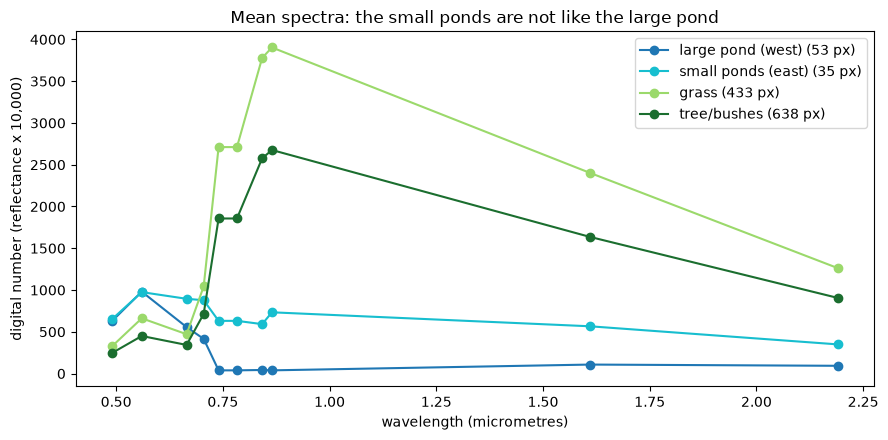

In [11]:
rf_ub = RF().fit(X_ub[west], y_ub[west])  # trained on the west (large pond)
pred_e = rf_ub.predict(X_ub[east])  # predictions for the east (small ponds)
rep_ub = ic.classification_report(y_ub[east], pred_e, labels=list(UB_CLASSES), class_names=UB_CLASSES)  # scores
display(rep_ub["per_class"].round(3))  # per-class precision, recall, F1
water_e = y_ub[east] == 5  # eastern water pixels
print("eastern water pixels predicted as:", pd.Series(pred_e[water_e]).map(UB_CLASSES).value_counts().to_dict())  # where the small-pond pixels went

wl = [0.490, 0.560, 0.665, 0.705, 0.740, 0.783, 0.842, 0.865, 1.610, 2.190]  # band centres (micrometres)
fig, ax = plt.subplots(figsize=(9, 4.5))  # one panel
for name, m, c in [("large pond (west)", west & (y_ub == 5), "#1f77b4"), ("small ponds (east)", east & (y_ub == 5), "#17becf"),
                   ("grass", y_ub == 4, "#9bd96b"), ("tree/bushes", y_ub == 3, "#1b6e2f")]:  # four groups
    ax.plot(wl, X_ub[m].mean(0), "o-", color=c, label=f"{name} ({m.sum()} px)")  # mean spectrum
ax.set(xlabel="wavelength (micrometres)", ylabel="digital number (reflectance x 10,000)",  # axes and title
       title="Mean spectra: the small ponds are not like the large pond")  # labels
ax.legend(); plt.tight_layout(); plt.show()  # legend, arrange and draw

The model finds only 4 of the 35 small-pond pixels and calls most of the others pavement. The spectra show why: the open water of the large pond is dark from the red edge onwards, while a small-pond pixel mixes water with its banks and vegetation, so its near-infrared and SWIR reflectance is many times higher, closer to pavement than to the large pond. This is a shift inside one class, caused by the size of the object relative to the pixel.


### CORAL: align the feature distributions

CORAL (Sun et al. 2016) is the simplest feature-level adaptation: it whitens the source features and re-colours them with the covariance and mean of the target domain, so that a model trained on the transformed source sees target-like statistics. `coral` needs only **unlabelled** target data. The target sample is the eastern image pixels that carry **no** label, so the test pixels are not used for the adaptation. The table compares the class recalls without and with CORAL.

CORAL aligns the whole distribution at once. That is right when the same classes occur in similar proportions and only the radiometry differs. Here the east also has a different mix of classes (far more trees and grass, fewer buildings), and CORAL cannot tell a change of class mix from a change of radiometry.


In [12]:
labelled_px = set(zip(ub.row, ub.col))  # pixels that carry a label
rr, cc = np.mgrid[:ub_img.shape[1], :ub_img.shape[2]]  # row and column of every image pixel
east_img = (ub_transform.c + (cc + 0.5) * ub_transform.a) >= UB_SPLIT_X  # eastern part of the image
adapt_rc = [(r, c) for r, c in zip(rr[east_img], cc[east_img]) if (r, c) not in labelled_px]  # unlabelled east pixels
ub_adapt_ids = [f"ub:{r}_{c}" for r, c in adapt_rc]  # their ids (for the isolation check)
X_adapt = ub_img[:, [r for r, _ in adapt_rc], [c for _, c in adapt_rc]].T  # their spectra
Xs_coral = ic.coral(X_ub[west], X_adapt)  # western features re-coloured to the eastern statistics
pred_c = RF().fit(Xs_coral, y_ub[west]).predict(X_ub[east])  # train on the aligned source
rec = lambda p: [np.mean(p[y_ub[east] == k] == k) for k in UB_CLASSES]  # recall per class
pd.DataFrame({"no adaptation": rec(pred_e) + [np.mean(pred_e == y_ub[east])],  # recall per class and overall accuracy
              "CORAL": rec(pred_c) + [np.mean(pred_c == y_ub[east])]},
             index=[*(f"recall {v}" for v in UB_CLASSES.values()), "overall accuracy"]).round(3)  # show it

,no adaptation,CORAL
recall Pavement/road,0.564,0.110
recall Building,0.459,0.685
recall Tree/bushes,0.781,0.703
recall Grass,0.797,0.093
recall Water,0.114,0.829
overall accuracy,0.688,0.412


**Reading the CORAL results.** CORAL raised the water recall from 11 % to 83 % and wrecked everything else: grass and pavement recall collapse and the overall accuracy falls from 69 % to 41 %. Forcing the western statistics to match an eastern area dominated by vegetation moved the class boundaries wholesale; the better water score is a side effect, not a fix. A domain-adaptation method can make one class look solved while the map gets worse, which is why both per-class and overall scores are needed. The reliable remedy for the small ponds is labelled small-pond pixels.


### Corn belt: from 2020 to 2025

The second shift is in time. A classifier trained on the 27 August 2020 image with the 2020 CDL is applied to the 26 August 2025 image. The crops are the same, but the dates within the season, the weather of the year, the sensor (Sentinel-2A or B against 2C) and the atmosphere differ. The splits are kept strictly apart:

- **source**: western pixels of 2020, with the 2020 CDL labels;
- **adapt**: western pixels of 2025, **without** labels, the only 2025 data any adaptation may look at;
- **test**: eastern pixels of 2025, scored against the 2025 CDL.

The table first shows how far the band means moved between the years.


In [13]:
Xs20, ys20 = features(2020, cb_train), cdl_at(2020, cb_train)  # source: 2020 west with labels
Xa25 = features(2025, cb_train)  # adapt: 2025 west, labels not used
shift = pd.DataFrame({"2020 west": Xs20.mean(0), "2025 west": Xa25.mean(0)}, index=list(img[2025].band.values))  # band means
shift["change %"] = 100 * (shift["2025 west"] / shift["2020 west"] - 1)  # relative change
shift.T.round(3)  # show it

,blue,green,red,rededge1,rededge2,rededge3,nir,nir08,swir16,swir22
2020 west,0.037,0.061,0.041,0.089,0.276,0.371,0.364,0.397,0.179,0.092
2025 west,0.028,0.052,0.032,0.089,0.303,0.386,0.402,0.414,0.183,0.087
change %,-25.862,-14.417,-21.379,-0.030,10.012,4.041,10.501,4.317,2.139,-6.009


Blue and red are about a fifth to a quarter lower in 2025 and the near-infrared about a tenth higher: a mix of a different atmosphere, a different satellite and processing, and crops that were greener at the end of August 2025 than in 2020.


### Histogram matching, CORAL and TENT

Three adaptations are compared with training on 2020 alone, and with the upper bound of training on labelled 2025 pixels:

- **`histogram_match`** maps every band of the 2020 source image so its histogram matches the 2025 image of the adapt area; the classifier is then trained on the matched 2020 image. It aligns each band separately.
- **`coral`** aligns the means and the covariance between the bands of the 2020 source pixels with the 2025 adapt pixels.
- **`tent_adapt`** (Wang et al. 2021) adapts a trained network at test time: it lets the batch-normalisation layers re-estimate their statistics on the target data and updates only their scale and shift to make the predictions on the unlabelled adapt pixels more confident (lower entropy). It needs a network with batch normalisation, so the small network of the noisy-label section is used, trained on 2020.


In [14]:
west_box = dict(x=slice(None, x_split - 1600))  # the western area (source and adapt)
hm20 = ic.histogram_match(img[2020].sel(**west_box), img[2025].sel(**west_box))  # 2020 matched to 2025, per band
west_cols = int((labels.x.values < x_split - 1600).sum())  # width of the western area
r_tr, c_tr = np.divmod(cb_train, W)  # row and column of the western sample
Xs_hm = hm20.values[:, r_tr, c_tr].T.astype("float32")  # matched 2020 features of the western sample
assert c_tr.max() < west_cols  # the sample lies inside the matched area

ds_rows = {}  # one row per method
ds_rows["train on 2020, no adaptation (RF)"] = report(ye, RF().fit(Xs20, ys20).predict(Xe), range(K))  # source only
ds_rows["histogram matching (RF)"] = report(ye, RF().fit(Xs_hm, ys20).predict(Xe), range(K))  # source matched to the 2025 histograms
ds_rows["CORAL (RF)"] = report(ye, RF().fit(ic.coral(Xs20, Xa25), ys20).predict(Xe), range(K))  # source aligned to the 2025 covariance

S_MU, S_SD = Xs20.mean(0), Xs20.std(0)  # scaling from the 2020 source only
to_t = lambda X: torch.tensor((X - S_MU) / S_SD, dtype=torch.float32)  # the same fixed scaling for every year
net20 = train_mlp(to_t(Xs20), ys20)  # network trained on 2020
Xe_s = to_t(Xe)  # 2025 test pixels with the source scaling
ds_rows["train on 2020, no adaptation (network)"] = report(ye, predict_mlp(net20, Xe_s), range(K))  # source only
# unlabelled 2025 pixels for adaptation
adapt_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(to_t(Xa25)), batch_size=512, shuffle=True)
net_tent, ent = ic.tent_adapt(copy.deepcopy(net20), adapt_loader, steps=1, lr=1e-3, device=DEVICE)  # TENT on 2025 west
ds_rows["TENT (network)"] = report(ye, predict_mlp(net_tent, Xe_s), range(K))  # after test-time adaptation
print(f"TENT: {len(ent)} batches, mean prediction entropy {ent[0]:.3f} -> {ent[-1]:.3f}")  # entropy before and after
# upper bound: trained on labelled 2025 pixels
ds_rows["upper bound: train on labelled 2025 west (RF)"] = report(ye, RF().fit(Xw, yw).predict(Xe), range(K))
pd.DataFrame(ds_rows).T.round(3)  # show the comparison

TENT: 59 batches, mean prediction entropy 0.266 -> 0.174


,overall accuracy,kappa,macro F1
"train on 2020, no adaptation (RF)",0.514,0.257,0.387
histogram matching (RF),0.892,0.808,0.538
CORAL (RF),0.899,0.822,0.570
"train on 2020, no adaptation (network)",0.448,0.309,0.365
TENT (network),0.898,0.820,0.582
upper bound: train on labelled 2025 west (RF),0.925,0.870,0.663


**Reading the year-to-year results.** Applied to 2025 without adaptation, the random forest and the network trained on 2020 fall to about half the accuracy of a 2025 model: much of the corn and soybean area crosses the class boundaries learned in 2020. All three adaptations, using only unlabelled 2025 pixels from the west, recover most of the gap, with about 89 % to 90 % against 92.5 % for a model trained on labelled 2025 pixels. This shift is mostly radiometric and global, the kind these methods are made for. TENT has one more ingredient: at prediction its batch-normalisation layers use the statistics of the batch being predicted (here all eastern test pixels at once), so it looks at the test images, though never at their labels.


## Check that the splits stayed apart

### `check_split_isolation`

Every method in this notebook has a set of data it may look at: the labelled pool, the unlabelled pool, the adaptation sample. None of them may contain a test sample, or the test score measures memory instead of generalisation. `check_split_isolation` takes named sets of sample ids and raises an error if any two overlap. The ids combine the dataset, the year and the pixel or chip, so the same location in two different years counts as two different samples. The last call shows what a violation looks like: adapting on the test pixels themselves.


In [15]:
pid = lambda year, pix: [f"cb{year}:{p}" for p in pix]  # corn belt pixel ids with the year
checks = {  # experiment -> named id sets that must not overlap
    "UB active learning": dict(pool=ub.id[west].tolist(), test=ub.id[east].tolist()),
    "UB CORAL": dict(train=ub.id[west].tolist(), adapt=ub_adapt_ids, test=ub.id[east].tolist()),
    "corn belt self-training and weak labels": dict(train=pid(2025, cb_train), test=pid(2025, cb_test)),
    "corn belt FixMatch": dict(labelled=[f"chip:{i}" for i in c_lab], test=[f"chip:{i}" for i in c_test]),
    "corn belt FixMatch, unlabelled": dict(unlabelled=[f"chip:{i}" for i in c_west], test=[f"chip:{i}" for i in c_test]),
    "corn belt 2020 to 2025": dict(source=pid(2020, cb_train), adapt=pid(2025, cb_train), test=pid(2025, cb_test)),
}
for name, sets in checks.items():  # every experiment
    print(f"{name:42s} isolated: {ic.check_split_isolation(**sets)}  ({', '.join(f'{k} {len(v)}' for k, v in sets.items())})")  # raises an error on any overlap

try:  # a deliberate leak: adapting on the test pixels
    # adaptation and test pixels must not overlap
    ic.check_split_isolation(adapt=pid(2025, cb_test[:1000]), test=pid(2025, cb_test))
except ValueError as err:  # the check refuses it
    print("leak detected:", err)  # the error message

UB active learning                         isolated: True  (pool 933, test 1202)
UB CORAL                                   isolated: True  (train 933, adapt 19708, test 1202)
corn belt self-training and weak labels    isolated: True  (train 30000, test 30000)
corn belt FixMatch                         isolated: True  (labelled 57, test 2284)
corn belt FixMatch, unlabelled             isolated: True  (unlabelled 5212, test 2284)
corn belt 2020 to 2025                     isolated: True  (source 30000, adapt 30000, test 30000)
leak detected: splits 'adapt' and 'test' share 1000 ids


## Interpretation and limitations

- **Active learning optimises for the pool.** On the UB campus the pool (west) differs from the test area (east), and the uncertainty rules lost to random sampling: they spent their labels on confusing roofs and parking lots that the test area hardly contains. Draw the pool from the whole mapping area, stratify the queries by region or class, and always compare with random sampling.
- **Pseudo-labels repeat what the model already knows.** Self-training added thousands of accurate pseudo-labels and changed the test score by less than a point. FixMatch amplified the class balance of its small labelled set and lost over 20 points of accuracy. Look at pseudo-label accuracy, mask rate and the class mix of the predictions, not only at one score.
- **Weak labels work when the product describes the same thing.** The cultivated layer and last year's CDL were almost as good as this year's CDL for crop / non-crop, because land use changes slowly. The rotation rule needed a confidence filter. Edge erosion raised label agreement but removed the thin non-crop features (roads, ditches, farmsteads) the map still has to classify, and lowered the test scores.
- **Noise-robust losses matter when the network can memorise.** With 30,000 samples and a small network, cross-entropy learned the majority label of each spectral region, so even 40 % symmetric noise or a 30 % corn/soybean swap barely moved the overall accuracy; GCE and SCE helped only the small classes at 40 % noise. Expect larger gains with few samples, large networks and long training.
- **Domain adaptation needs the right kind of shift.** For the global radiometric shift between 2020 and 2025, histogram matching, CORAL and TENT all recovered most of a 40-point loss. On the UB campus, where the shift was a different class mix and a different water spectrum, CORAL raised water recall but destroyed the rest of the map. Score every class and the overall accuracy before and after adapting.
- **Isolation.** Every adaptation here used a separate unlabelled sample, and `check_split_isolation` confirms it. Choosing thresholds, losses or adaptation methods by their test score, as a comparison notebook does, is itself a mild form of leakage; in a real project, choose on a validation area and report the test area once.

### References

- Settles, B. (2009). Active learning literature survey. University of Wisconsin-Madison, Computer Sciences Technical Report 1648.
- Sohn, K., et al. (2020). FixMatch: simplifying semi-supervised learning with consistency and confidence. NeurIPS.
- Zhang, Z., Sabuncu, M. (2018). Generalized cross entropy loss for training deep neural networks with noisy labels. NeurIPS.
- Wang, Y., Ma, X., Chen, Z., et al. (2019). Symmetric cross entropy for robust learning with noisy labels. ICCV.
- Sun, B., Feng, J., Saenko, K. (2016). Return of frustratingly easy domain adaptation (CORAL). AAAI.
- Wang, D., Shelhamer, E., Liu, S., Olshausen, B., Darrell, T. (2021). Tent: fully test-time adaptation by entropy minimization. ICLR.
- Tuia, D., Persello, C., Bruzzone, L. (2016). Domain adaptation for the classification of remote sensing data: an overview of recent advances. IEEE Geoscience and Remote Sensing Magazine.
- USDA NASS Cropland Data Layer and Cultivated Layer. https://www.nass.usda.gov/Research_and_Science/Cropland/
